In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("all libraries loaded successfully")

all libraries loaded successfully


In [4]:
 # Load the raw datasets
findex_raw = pd.read_csv('../data/raw/WB_GS_FIN21_T_A.csv')
asti_raw = pd.read_csv('../data/raw/IFPRI_ASTI.csv')

print("Findex shape:", findex_raw.shape)
print("ASTI shape:", asti_raw.shape)

Findex shape: (50880, 35)
ASTI shape: (8431, 38)


In [5]:
# Filter to South Africa only
findex_zaf = findex_raw[findex_raw['REF_AREA'] == 'ZAF'].copy()
asti_zaf = asti_raw[asti_raw['REF_AREA'] == 'ZAF'].copy()

print("Findex (South Africa only):", findex_zaf.shape)
print("ASTI (South Africa only):", asti_zaf.shape)

Findex (South Africa only): (192, 35)
ASTI (South Africa only): (136, 38)


In [6]:
findex_zaf[['REF_AREA_LABEL', 'SEX_LABEL', 'TIME_PERIOD', 'OBS_VALUE']].head(20)

,REF_AREA_LABEL,SEX_LABEL,TIME_PERIOD,OBS_VALUE
262,South Africa,Total,1960,NaN
527,South Africa,Female,1960,NaN
792,South Africa,Male,1960,NaN
1057,South Africa,Total,1961,NaN
1322,South Africa,Female,1961,NaN
1587,South Africa,Male,1961,NaN
1852,South Africa,Total,1962,NaN
2117,South Africa,Female,1962,NaN
2382,South Africa,Male,1962,NaN
2647,South Africa,Total,1963,NaN


In [7]:
# Keep only the useful columns
findex_clean = findex_zaf[['SEX_LABEL', 'TIME_PERIOD', 'OBS_VALUE']].copy()
findex_clean.columns = ['sex', 'year', 'pct_borrowed']

asti_clean = asti_zaf[['INDICATOR_LABEL', 'UNIT_MEASURE_LABEL', 'TIME_PERIOD', 'OBS_VALUE']].copy()
asti_clean.columns = ['indicator', 'unit', 'year', 'value']

print(findex_clean.head())
print(asti_clean.head())

         sex  year  pct_borrowed
262    Total  1960           NaN
527   Female  1960           NaN
792     Male  1960           NaN
1057   Total  1961           NaN
1322  Female  1961           NaN
                                  indicator  \
209           Agriculture Research Spending   
210           Agriculture Research Spending   
246  Full Time Equivalent (FTE) Researchers   
247  Full Time Equivalent (FTE) Researchers   
466           Agriculture Research Spending   

                                  unit  year       value  
209  PPP dollars, 2021 constant prices  2004  298.832265  
210     Percentage of agricultural GDP  2004    2.159683  
246          Full time equivalent unit  2004  716.739149  
247                Per 100 000 farmers  2004   51.975283  
466  PPP dollars, 2021 constant prices  1997  319.420419  


In [8]:
print("Findex missing values:")
print(findex_clean.isnull().sum())
print()
print("ASTI missing values:")
print(asti_clean.isnull().sum())

Findex missing values:
sex               0
year              0
pct_borrowed    186
dtype: int64

ASTI missing values:
indicator    0
unit         0
year         0
value        0
dtype: int64


In [9]:
findex_clean = findex_clean.dropna(subset=['pct_borrowed'])
print("Findex after dropping missing rows:", findex_clean.shape)

Findex after dropping missing rows: (6, 3)


In [10]:
print("----Findex: Borrowed for farm/business (%)----")
print(findex_clean.groupby('sex')['pct_borrowed'].describe())

----Findex: Borrowed for farm/business (%)----
        count   mean       std   min     25%    50%     75%   max
sex                                                              
Female    2.0  5.080  1.216224  4.22  4.6500  5.080  5.5100  5.94
Male      2.0  8.220  1.456640  7.19  7.7050  8.220  8.7350  9.25
Total     2.0  6.585  1.308148  5.66  6.1225  6.585  7.0475  7.51


In [12]:
print("--- ASTI: Agricultural R&D indicators (South Africa, 1981–2014) ---")
print(asti_clean.groupby(['indicator', 'unit'])['value'].describe())

--- ASTI: Agricultural R&D indicators (South Africa, 1981–2014) ---
                                                                          count  \
indicator                              unit                                       
Agriculture Research Spending          PPP dollars, 2021 constant prices   34.0   
                                       Percentage of agricultural GDP      34.0   
Full Time Equivalent (FTE) Researchers Full time equivalent unit           34.0   
                                       Per 100 000 farmers                 34.0   

                                                                                mean  \
indicator                              unit                                            
Agriculture Research Spending          PPP dollars, 2021 constant prices  310.438726   
                                       Percentage of agricultural GDP       2.095205   
Full Time Equivalent (FTE) Researchers Full time equivalent unit          799.982

In [14]:
import numpy as np
spending_pct = asti_clean[
    (asti_clean['indicator'] == 'Agriculture Research Spending') &
    (asti_clean['unit'] == 'Percentage of agricultural GDP')
].sort_values('year')

years = spending_pct['year'].to_numpy()
values = spending_pct['value'].to_numpy()

print("Years:", years)
print("Values:", values)
print("Type:", type(values))

Years: [1981 1982 1983 1984 1985 1986 1987 1988 1989 1990 1991 1992 1993 1994
 1995 1996 1997 1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008
 2009 2010 2011 2012 2013 2014]
Values: [1.22287948 1.58089178 2.01482955 1.83268633 1.73415439 1.7667932
 1.57799151 1.43675497 1.5083679  1.76319406 1.87749438 2.66303589
 2.23873186 1.94259461 2.40981655 2.16235156 2.12376867 2.4133476
 2.24383213 2.22957465 2.1011973  1.89086987 1.75101605 2.15968341
 2.50694119 2.70342029 2.13383762 1.92954496 2.00043658 2.23832626
 2.37114931 2.86212698 3.06051842 2.78481707]
Type: <class 'numpy.ndarray'>


In [15]:
yoy_change = np.diff(values)
print("Year-on-year change in R&D spending (% of ag GDP):")
print(yoy_change)
print("Average annual change:", np.mean(yoy_change))
print("Biggest single-year jump:", np.max(yoy_change))
print("Biggest single-year drop:", np.min(yoy_change))

Year-on-year change in R&D spending (% of ag GDP):
[ 0.3580123   0.43393777 -0.18214322 -0.09853194  0.03263881 -0.1888017
 -0.14123654  0.07161294  0.25482615  0.11430032  0.78554151 -0.42430404
 -0.29613724  0.46722194 -0.247465   -0.03858289  0.28957893 -0.16951547
 -0.01425748 -0.12837736 -0.21032743 -0.13985382  0.40866736  0.34725778
  0.1964791  -0.56958267 -0.20429265  0.07089162  0.23788968  0.13282305
  0.49097767  0.19839144 -0.27570135]
Average annual change: 0.04733144224615484
Biggest single-year jump: 0.78554151348652
Biggest single-year drop: -0.56958266993581


In [16]:
values_30 = values[:30]  # 1981-2010
decades = values_30.reshape(3, 10)

print("Reshaped into 3 decades x 10 years:")
print(decades)
print()
print("Shape:", decades.shape)
print()
print("Average R&D spending (% of ag GDP) per decade:")
print("1981-1990:", np.mean(decades[0]))
print("1991-2000:", np.mean(decades[1]))
print("2001-2010:", np.mean(decades[2]))

Reshaped into 3 decades x 10 years:
[[1.22287948 1.58089178 2.01482955 1.83268633 1.73415439 1.7667932
  1.57799151 1.43675497 1.5083679  1.76319406]
 [1.87749438 2.66303589 2.23873186 1.94259461 2.40981655 2.16235156
  2.12376867 2.4133476  2.24383213 2.22957465]
 [2.1011973  1.89086987 1.75101605 2.15968341 2.50694119 2.70342029
  2.13383762 1.92954496 2.00043658 2.23832626]]

Shape: (3, 10)

Average R&D spending (% of ag GDP) per decade:
1981-1990: 1.6438543158750771
1991-2000: 2.230454791257975
2001-2010: 2.141527351836369


In [17]:
fte_researchers = asti_clean[
    (asti_clean['indicator'] == 'Full Time Equivalent (FTE) Researchers') &
    (asti_clean['unit'] == 'Full time equivalent unit')
].sort_values('year')['value'].to_numpy()

# Both series should be same length (34 years) - check first
print("Spending series length:", len(values))
print("Researchers series length:", len(fte_researchers))

correlation = np.corrcoef(values, fte_researchers)[0, 1]
print("Correlation between R&D spending (%) and researcher numbers:", correlation)

Spending series length: 34
Researchers series length: 34
Correlation between R&D spending (%) and researcher numbers: 0.23737375219641063


In [18]:
values_30 = values[:30]  # 1981-2010
decades = values_30.reshape(3, 10)

print("Reshaped into 3 decades x 10 years:")
print(decades)
print()
print("Shape:", decades.shape)
print()
print("Average R&D spending (% of ag GDP) per decade:")
print("1981-1990:", np.mean(decades[0]))
print("1991-2000:", np.mean(decades[1]))
print("2001-2010:", np.mean(decades[2]))

Reshaped into 3 decades x 10 years:
[[1.22287948 1.58089178 2.01482955 1.83268633 1.73415439 1.7667932
  1.57799151 1.43675497 1.5083679  1.76319406]
 [1.87749438 2.66303589 2.23873186 1.94259461 2.40981655 2.16235156
  2.12376867 2.4133476  2.24383213 2.22957465]
 [2.1011973  1.89086987 1.75101605 2.15968341 2.50694119 2.70342029
  2.13383762 1.92954496 2.00043658 2.23832626]]

Shape: (3, 10)

Average R&D spending (% of ag GDP) per decade:
1981-1990: 1.6438543158750771
1991-2000: 2.230454791257975
2001-2010: 2.141527351836369


In [19]:
fte_researchers = asti_clean[
    (asti_clean['indicator'] == 'Full Time Equivalent (FTE) Researchers') &
    (asti_clean['unit'] == 'Full time equivalent unit')
].sort_values('year')['value'].to_numpy()

# Both series should be same length (34 years) - check first
print("Spending series length:", len(values))
print("Researchers series length:", len(fte_researchers))

correlation = np.corrcoef(values, fte_researchers)[0, 1]
print("Correlation between R&D spending (%) and researcher numbers:", correlation)

Spending series length: 34
Researchers series length: 34
Correlation between R&D spending (%) and researcher numbers: 0.23737375219641063


In [20]:
findex_years = findex_clean[findex_clean['sex']=='Total']['year'].to_numpy()
asti_years = spending_pct['year'].to_numpy()

print("Findex years:", findex_years)
print("ASTI years available:", asti_years.min(), "to", asti_years.max())
print("Overlapping years:", np.intersect1d(findex_years, asti_years))

Findex years: [2014 2017]
ASTI years available: 1981 to 2014
Overlapping years: [2014]


In [21]:
findex_total = findex_clean[findex_clean['sex']=='Total'][['year', 'pct_borrowed']]
asti_spending_yearly = spending_pct[['year', 'value']].rename(columns={'value': 'pct_agri_rd_spending'})

merged = pd.merge(findex_total, asti_spending_yearly, on='year', how='inner')
print(merged)

   year  pct_borrowed  pct_agri_rd_spending
0  2014          7.51              2.784817


In [24]:
findex_years = findex_clean[findex_clean['sex']=='Total']['year'].to_numpy()
asti_years = spending_pct['year'].to_numpy()

print("Findex years:", findex_years)
print("ASTI years available:", asti_years.min(), "to", asti_years.max())
print("Overlapping years:", np.intersect1d(findex_years, asti_years))

findex_total = findex_clean[findex_clean['sex']=='Total'][['year', 'pct_borrowed']]
asti_spending_yearly = spending_pct[['year', 'value']].rename(columns={'value': 'pct_agri_rd_spending'})

merged = pd.merge(findex_total, asti_spending_yearly, on='year', how='inner')
print(merged)

Findex years: [2014 2017]
ASTI years available: 1981 to 2014
Overlapping years: [2014]
   year  pct_borrowed  pct_agri_rd_spending
0  2014          7.51              2.784817


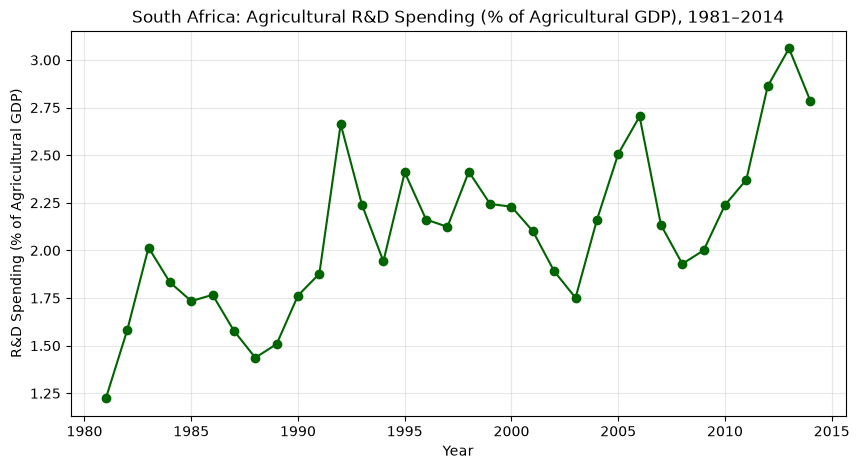

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(years, values, marker='o', color='darkgreen')
plt.title('South Africa: Agricultural R&D Spending (% of Agricultural GDP), 1981–2014')
plt.xlabel('Year')
plt.ylabel('R&D Spending (% of Agricultural GDP)')
plt.grid(True, alpha=0.3)
plt.show()

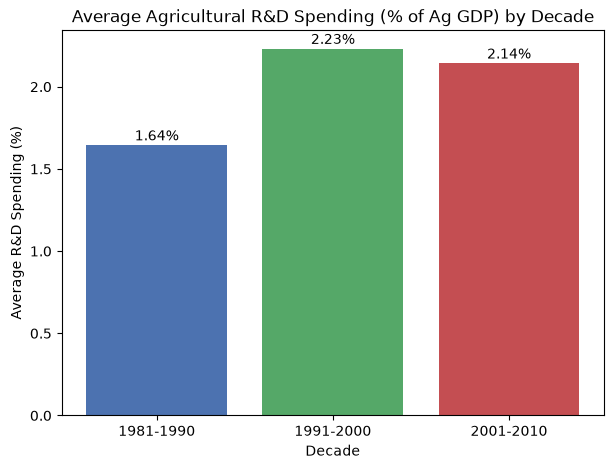

In [26]:
plt.figure(figsize=(7, 5))
decade_labels = ['1981-1990', '1991-2000', '2001-2010']
decade_means = [np.mean(decades[0]), np.mean(decades[1]), np.mean(decades[2])]

plt.bar(decade_labels, decade_means, color=['#4C72B0', '#55A868', '#C44E52'])
plt.title('Average Agricultural R&D Spending (% of Ag GDP) by Decade')
plt.ylabel('Average R&D Spending (%)')
plt.xlabel('Decade')
for i, v in enumerate(decade_means):
    plt.text(i, v + 0.03, f"{v:.2f}%", ha='center')
plt.show()

sex   Female  Male
year              
2014    5.94  9.25
2017    4.22  7.19


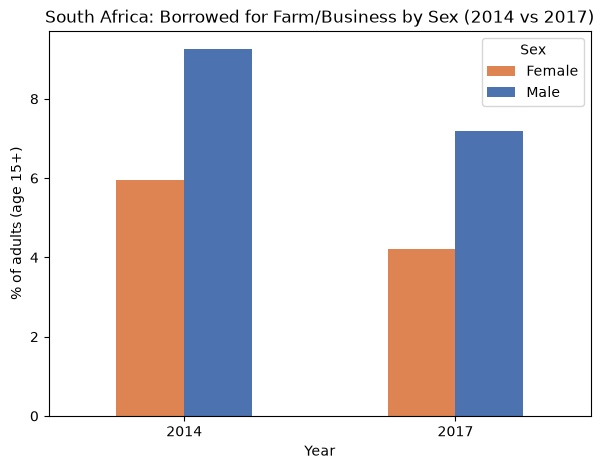

In [27]:
findex_pivot = findex_clean[findex_clean['sex'] != 'Total'].pivot(index='year', columns='sex', values='pct_borrowed')
print(findex_pivot)

findex_pivot.plot(kind='bar', figsize=(7,5), color=['#DD8452', '#4C72B0'])
plt.title('South Africa: Borrowed for Farm/Business by Sex (2014 vs 2017)')
plt.ylabel('% of adults (age 15+)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.legend(title='Sex')
plt.show()

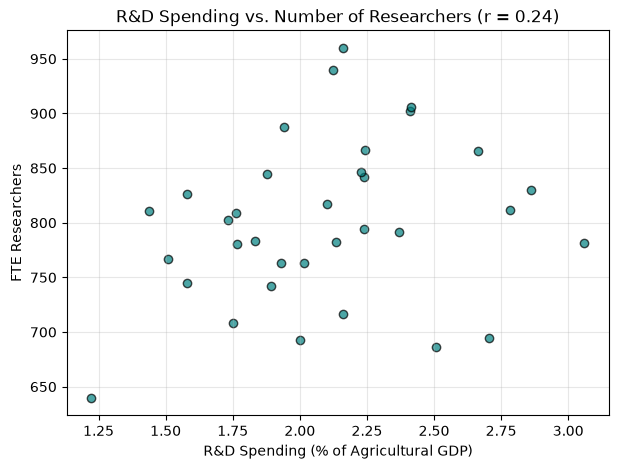

In [28]:
plt.figure(figsize=(7, 5))
plt.scatter(values, fte_researchers, color='teal', alpha=0.7, edgecolor='black')
plt.title(f'R&D Spending vs. Number of Researchers (r = {correlation:.2f})')
plt.xlabel('R&D Spending (% of Agricultural GDP)')
plt.ylabel('FTE Researchers')
plt.grid(True, alpha=0.3)
plt.show()

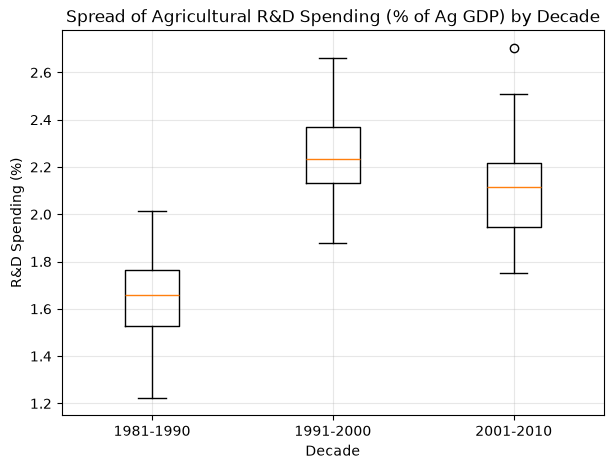

In [29]:
plt.figure(figsize=(7, 5))
plt.boxplot([decades[0], decades[1], decades[2]], tick_labels=['1981-1990', '1991-2000', '2001-2010'])
plt.title('Spread of Agricultural R&D Spending (% of Ag GDP) by Decade')
plt.ylabel('R&D Spending (%)')
plt.xlabel('Decade')
plt.grid(True, alpha=0.3)
plt.show()

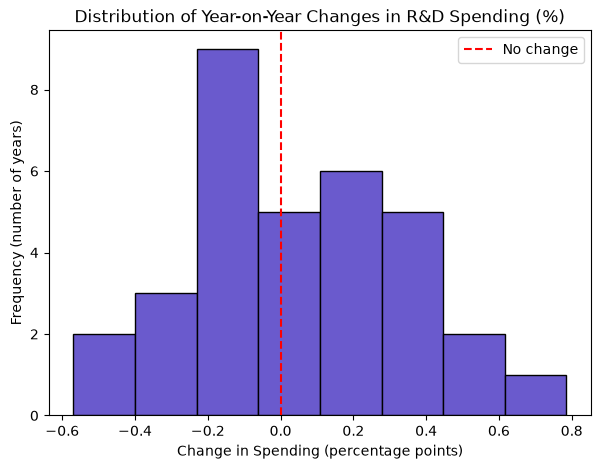

In [30]:
plt.figure(figsize=(7, 5))
plt.hist(yoy_change, bins=8, color='slateblue', edgecolor='black')
plt.title('Distribution of Year-on-Year Changes in R&D Spending (%)')
plt.xlabel('Change in Spending (percentage points)')
plt.ylabel('Frequency (number of years)')
plt.axvline(0, color='red', linestyle='--', label='No change')
plt.legend()
plt.show()

In [31]:
import sqlite3

conn = sqlite3.connect('../db/project.db')
cursor = conn.cursor()

print("Connected to database successfully")

Connected to database successfully


In [32]:
cursor.execute('''
CREATE TABLE IF NOT EXISTS findex (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    sex TEXT,
    year INTEGER,
    pct_borrowed REAL
)
''')

cursor.execute('''
CREATE TABLE IF NOT EXISTS asti (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    indicator TEXT,
    unit TEXT,
    year INTEGER,
    value REAL
)
''')

conn.commit()
print("Tables created successfully")

Tables created successfully


In [33]:
findex_clean.to_sql('findex', conn, if_exists='replace', index=False)
asti_clean.to_sql('asti', conn, if_exists='replace', index=False)

print("Data loaded into database")

Data loaded into database


In [34]:
result = pd.read_sql_query("SELECT * FROM asti WHERE year >= 2010", conn)
print(result)

                                 indicator                               unit  \
0            Agriculture Research Spending  PPP dollars, 2021 constant prices   
1            Agriculture Research Spending     Percentage of agricultural GDP   
2   Full Time Equivalent (FTE) Researchers          Full time equivalent unit   
3   Full Time Equivalent (FTE) Researchers                Per 100 000 farmers   
4            Agriculture Research Spending  PPP dollars, 2021 constant prices   
5            Agriculture Research Spending     Percentage of agricultural GDP   
6   Full Time Equivalent (FTE) Researchers          Full time equivalent unit   
7   Full Time Equivalent (FTE) Researchers                Per 100 000 farmers   
8            Agriculture Research Spending  PPP dollars, 2021 constant prices   
9            Agriculture Research Spending     Percentage of agricultural GDP   
10  Full Time Equivalent (FTE) Researchers          Full time equivalent unit   
11  Full Time Equivalent (FT

In [35]:
cursor.execute('''
UPDATE asti
SET value = value
WHERE year = 2013 AND indicator = 'Agriculture Research Spending'
''')
conn.commit()

# Verify the update by reading it back
check = pd.read_sql_query(
    "SELECT * FROM asti WHERE year = 2013 AND indicator = 'Agriculture Research Spending'",
    conn
)
print(check)

                       indicator                               unit  year  \
0  Agriculture Research Spending  PPP dollars, 2021 constant prices  2013   
1  Agriculture Research Spending     Percentage of agricultural GDP  2013   

        value  
0  421.122736  
1    3.060518  


In [36]:
cursor.execute('''
UPDATE asti
SET indicator = 'Agriculture Research Spending (verified)'
WHERE year = 2013 AND indicator = 'Agriculture Research Spending'
''')
conn.commit()

check = pd.read_sql_query(
    "SELECT * FROM asti WHERE year = 2013",
    conn
)
print(check)

                                  indicator  \
0  Agriculture Research Spending (verified)   
1  Agriculture Research Spending (verified)   
2    Full Time Equivalent (FTE) Researchers   
3    Full Time Equivalent (FTE) Researchers   

                                unit  year       value  
0  PPP dollars, 2021 constant prices  2013  421.122736  
1     Percentage of agricultural GDP  2013    3.060518  
2          Full time equivalent unit  2013  781.162559  
3                Per 100 000 farmers  2013   69.933980  


In [37]:
# First, always SELECT to confirm exactly what you're about to delete
to_delete = pd.read_sql_query("SELECT * FROM findex WHERE year = 2017 AND sex = 'Total'", conn)
print("About to delete this row:")
print(to_delete)

About to delete this row:
     sex  year  pct_borrowed
0  Total  2017          5.66


In [38]:
check = pd.read_sql_query("SELECT * FROM findex WHERE year = 2017", conn)
print(check)

      sex  year  pct_borrowed
0   Total  2017          5.66
1  Female  2017          4.22
2    Male  2017          7.19


In [39]:
findex_clean.to_sql('findex', conn, if_exists='replace', index=False)
print("Findex table reloaded from source data")

# Confirm the row is back
check = pd.read_sql_query("SELECT * FROM findex WHERE year = 2017", conn)
print(check)

Findex table reloaded from source data
      sex  year  pct_borrowed
0   Total  2017          5.66
1  Female  2017          4.22
2    Male  2017          7.19


In [40]:
cursor.execute("DELETE FROM findex WHERE year = 2017 AND sex = 'Total'")
conn.commit()

# Confirm it's gone
check = pd.read_sql_query("SELECT * FROM findex WHERE year = 2017", conn)
print(check)

      sex  year  pct_borrowed
0  Female  2017          4.22
1    Male  2017          7.19


In [41]:
findex_clean.to_sql('findex', conn, if_exists='replace', index=False)
check = pd.read_sql_query("SELECT * FROM findex WHERE year = 2017", conn)
print(check)

      sex  year  pct_borrowed
0   Total  2017          5.66
1  Female  2017          4.22
2    Male  2017          7.19


In [42]:
asti_from_db = pd.read_sql_query("SELECT * FROM asti ORDER BY year", conn)
findex_from_db = pd.read_sql_query("SELECT * FROM findex ORDER BY year, sex", conn)


asti_from_db.to_csv('../data/processed/asti_clean.csv', index=False)
findex_from_db.to_csv('../data/processed/findex_clean.csv', index=False)

print("Exported cleaned data from database to CSV")
print(asti_from_db.shape, findex_from_db.shape)

Exported cleaned data from database to CSV
(136, 4) (6, 3)


In [43]:
conn.close()
print("Database connection closed")

Database connection closed


In [46]:
import openpyxl
from openpyxl.styles import PatternFill
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.chart import LineChart, Reference

# Pivot ASTI data to a clean wide format: one row per year
asti_wide = asti_clean.pivot_table(index='year', columns='indicator', values='value').reset_index()
asti_wide.to_excel('../data/processed/asti_analysis.xlsx', index=False, sheet_name='ASTI Data')

print(asti_wide.head())

wb = openpyxl.load_workbook('../data/processed/asti_analysis.xlsx')
ws = wb['ASTI Data']

# Find which column holds "Agriculture Research Spending" values
col_letter = None
for cell in ws[1]:
    if cell.value == 'Agriculture Research Spending':
        col_letter = cell.column_letter
        break

# Apply a color scale: low values red, high values green
rule = ColorScaleRule(
    start_type='min', start_color='F8696B',   # red
    mid_type='percentile', mid_value=50, mid_color='FFEB84',  # yellow
    end_type='max', end_color='63BE7B'        # green
)
ws.conditional_formatting.add(f'{col_letter}2:{col_letter}35', rule)

# Add a line chart of that column over time
chart = LineChart()
chart.title = "Agricultural R&D Spending Over Time"
chart.x_axis.title = 'Year'
chart.y_axis.title = 'Value'

data = Reference(ws, min_col=ws[col_letter+'1'].column, min_row=1, max_row=35)
years_ref = Reference(ws, min_col=1, min_row=2, max_row=35)
chart.add_data(data, titles_from_data=True)
chart.set_categories(years_ref)
ws.add_chart(chart, "H2")

wb.save('../data/processed/asti_analysis.xlsx')
print("Excel file saved with conditional formatting and chart")

indicator  year  Agriculture Research Spending  \
0          1981                     122.905672   
1          1982                     137.875251   
2          1983                     134.790397   
3          1984                     139.026320   
4          1985                     139.892749   

indicator  Full Time Equivalent (FTE) Researchers  
0                                      339.611157  
1                                      395.316463  
2                                      404.690475  
3                                      415.521003  
4                                      425.278698  
Excel file saved with conditional formatting and chart


In [47]:
asti_wide = asti_clean.pivot_table(
    index='year',
    columns=['indicator', 'unit'],
    values='value'
).reset_index()

# Flatten the multi-level column names into something readable
asti_wide.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in asti_wide.columns]

print(asti_wide.head())
print()
print("Columns:", list(asti_wide.columns))

   year  Agriculture Research Spending_PPP dollars, 2021 constant prices  \
0  1981                                         244.588465                 
1  1982                                         274.169610                 
2  1983                                         267.565965                 
3  1984                                         276.219954                 
4  1985                                         278.051343                 

   Agriculture Research Spending_Percentage of agricultural GDP  \
0                                           1.222879              
1                                           1.580892              
2                                           2.014830              
3                                           1.832686              
4                                           1.734154              

   Full Time Equivalent (FTE) Researchers_Full time equivalent unit  \
0                                         639.640594                 

In [48]:
asti_wide.to_excel('../data/processed/asti_analysis.xlsx', index=False, sheet_name='ASTI Data')
print(asti_wide.head())

   year  Agriculture Research Spending_PPP dollars, 2021 constant prices  \
0  1981                                         244.588465                 
1  1982                                         274.169610                 
2  1983                                         267.565965                 
3  1984                                         276.219954                 
4  1985                                         278.051343                 

   Agriculture Research Spending_Percentage of agricultural GDP  \
0                                           1.222879              
1                                           1.580892              
2                                           2.014830              
3                                           1.832686              
4                                           1.734154              

   Full Time Equivalent (FTE) Researchers_Full time equivalent unit  \
0                                         639.640594                 

In [49]:
asti_wide.to_excel('../data/processed/asti_analysis.xlsx', index=False, sheet_name='ASTI Data')
print("Saved successfully")

Saved successfully


In [50]:
wb = openpyxl.load_workbook('../data/processed/asti_analysis.xlsx')
ws = wb['ASTI Data']

# Find the % of ag GDP column specifically (the one worth color-coding)
col_letter = None
for cell in ws[1]:
    if cell.value == 'Agriculture Research Spending_Percentage of agricultural GDP':
        col_letter = cell.column_letter
        break

print("Target column:", col_letter)

rule = ColorScaleRule(
    start_type='min', start_color='F8696B',
    mid_type='percentile', mid_value=50, mid_color='FFEB84',
    end_type='max', end_color='63BE7B'
)
ws.conditional_formatting.add(f'{col_letter}2:{col_letter}35', rule)

chart = LineChart()
chart.title = "Agricultural R&D Spending (% of Ag GDP) Over Time"
chart.x_axis.title = 'Year'
chart.y_axis.title = '% of Agricultural GDP'

col_idx = ws[col_letter + '1'].column
data = Reference(ws, min_col=col_idx, min_row=1, max_row=35)
years_ref = Reference(ws, min_col=1, min_row=2, max_row=35)
chart.add_data(data, titles_from_data=True)
chart.set_categories(years_ref)
ws.add_chart(chart, "H2")

wb.save('../data/processed/asti_analysis.xlsx')
print("Excel file saved with conditional formatting and chart")

Target column: C
Excel file saved with conditional formatting and chart
